In [ ]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import os

from src.data_loader import *
from src.models import *
from src.trainer import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Carregamento dos dados:

In [4]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


# Parte 0 — O piso:

### 0.0: Carregamento dos dados de treino (Supervisionados)

In [5]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


### 0.1: Treinem um classificador supervisionado só com rotulos_5.csv (105 imagens), em duas versões: 

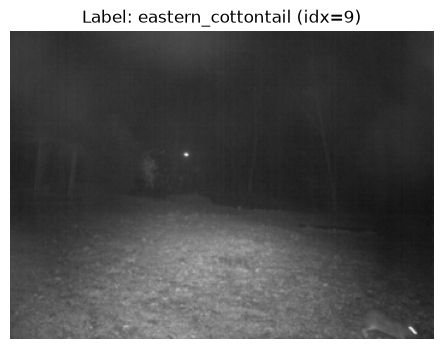

In [6]:
# Carrega o orçamento padrão de 5 rótulos por classe (105 imagens no treino)
train_loader_5, val_loader, test_loader = get_supervised_dataloaders(
    root_dir=root,
    labels_qtt=5,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42
)

# Visualizando uma amostra do train_loader_5 (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_5))
img_sample = images[0].permute(1, 2, 0).numpy()
img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

plt.figure(figsize=(6, 4))
plt.imshow(img_sample)
plt.title(f"Label: {idx_to_label[labels[0].item()]} (idx={labels[0].item()})")
plt.axis("off")
plt.show()

#### (a) uma CNN pequena treinada do zero; 

In [7]:
cnn_zero = build_model("small_cnn", num_classes=21).to(device)
print(f"Treinando SmallCNN do zero ({count_parameters(cnn_zero):,} parâmetros)...")

cnn_zero, hist_cnn = train_model(
    model=cnn_zero,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="small_cnn",
    epochs=50,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_small_cnn_b5_s42.pt",
    seed=42
)

Treinando SmallCNN do zero (394,293 parâmetros)...
Época [01/50] Train Loss: 3.1481 | Train F1: 0.038 || Val Loss: 3.0388 | Val F1: 0.015 (Acc: 0.054) [Novo Melhor Val F1]
Época [02/50] Train Loss: 2.8068 | Train F1: 0.150 || Val Loss: 3.0387 | Val F1: 0.017 (Acc: 0.059) [Novo Melhor Val F1]
Época [03/50] Train Loss: 2.7551 | Train F1: 0.104 || Val Loss: 3.0304 | Val F1: 0.046 (Acc: 0.079) [Novo Melhor Val F1]
Época [04/50] Train Loss: 2.6008 | Train F1: 0.163 || Val Loss: 2.9426 | Val F1: 0.086 (Acc: 0.134) [Novo Melhor Val F1]
Época [05/50] Train Loss: 2.6082 | Train F1: 0.130 || Val Loss: 2.8976 | Val F1: 0.098 (Acc: 0.144) [Novo Melhor Val F1]
Época [06/50] Train Loss: 2.5014 | Train F1: 0.154 || Val Loss: 2.8378 | Val F1: 0.142 (Acc: 0.183) [Novo Melhor Val F1]
Época [10/50] Train Loss: 2.3860 | Train F1: 0.235 || Val Loss: 2.8498 | Val F1: 0.128 (Acc: 0.153)
Época [15/50] Train Loss: 2.2978 | Train F1: 0.215 || Val Loss: 2.9683 | Val F1: 0.107 (Acc: 0.139)
Época [19/50] Train Los

#### (b) o backbone que vocês vão usar no resto do PA, partindo do ImageNet, com fine-tuning.

In [8]:
resnet_piso = build_model("resnet18", num_classes=21, pretrained=True).to(device)
print(f"Treinando ResNet-18 ImageNet ({count_parameters(resnet_piso):,} parâmetros)...")

resnet_piso, hist_resnet = train_model(
    model=resnet_piso,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="resnet18",
    epochs=40,
    lr_backbone=1e-4,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_resnet18_b5_s42.pt",
    seed=42
)

Treinando ResNet-18 ImageNet (11,187,285 parâmetros)...
Época [01/40] Train Loss: 3.2422 | Train F1: 0.054 || Val Loss: 2.8372 | Val F1: 0.130 (Acc: 0.168) [Novo Melhor Val F1]
Época [02/40] Train Loss: 2.0864 | Train F1: 0.547 || Val Loss: 2.4941 | Val F1: 0.263 (Acc: 0.282) [Novo Melhor Val F1]
Época [03/40] Train Loss: 1.4582 | Train F1: 0.712 || Val Loss: 2.2498 | Val F1: 0.273 (Acc: 0.282) [Novo Melhor Val F1]
Época [04/40] Train Loss: 1.0104 | Train F1: 0.901 || Val Loss: 2.1591 | Val F1: 0.296 (Acc: 0.282) [Novo Melhor Val F1]
Época [05/40] Train Loss: 0.7826 | Train F1: 0.896 || Val Loss: 2.1504 | Val F1: 0.355 (Acc: 0.356) [Novo Melhor Val F1]
Época [06/40] Train Loss: 0.5453 | Train F1: 0.934 || Val Loss: 2.1165 | Val F1: 0.366 (Acc: 0.361) [Novo Melhor Val F1]
Época [08/40] Train Loss: 0.3073 | Train F1: 0.990 || Val Loss: 2.0738 | Val F1: 0.378 (Acc: 0.366) [Novo Melhor Val F1]
Época [10/40] Train Loss: 0.1883 | Train F1: 0.981 || Val Loss: 2.1083 | Val F1: 0.351 (Acc: 0.32

### 0.2: Avaliação no `test_public` (F1 Macro e Acurácia) e Matriz de Confusão da versão (b)

Comparativo da Parte 0 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Val F1 Macro (Melhor),Test F1 Macro,Test Acurácia
0,0.1 (a) SmallCNN (do zero),394293,0.2341,0.2100,0.2306
1,0.1 (b) ResNet-18 (ImageNet Fine-Tuning),11187285,0.3816,0.4559,0.4723


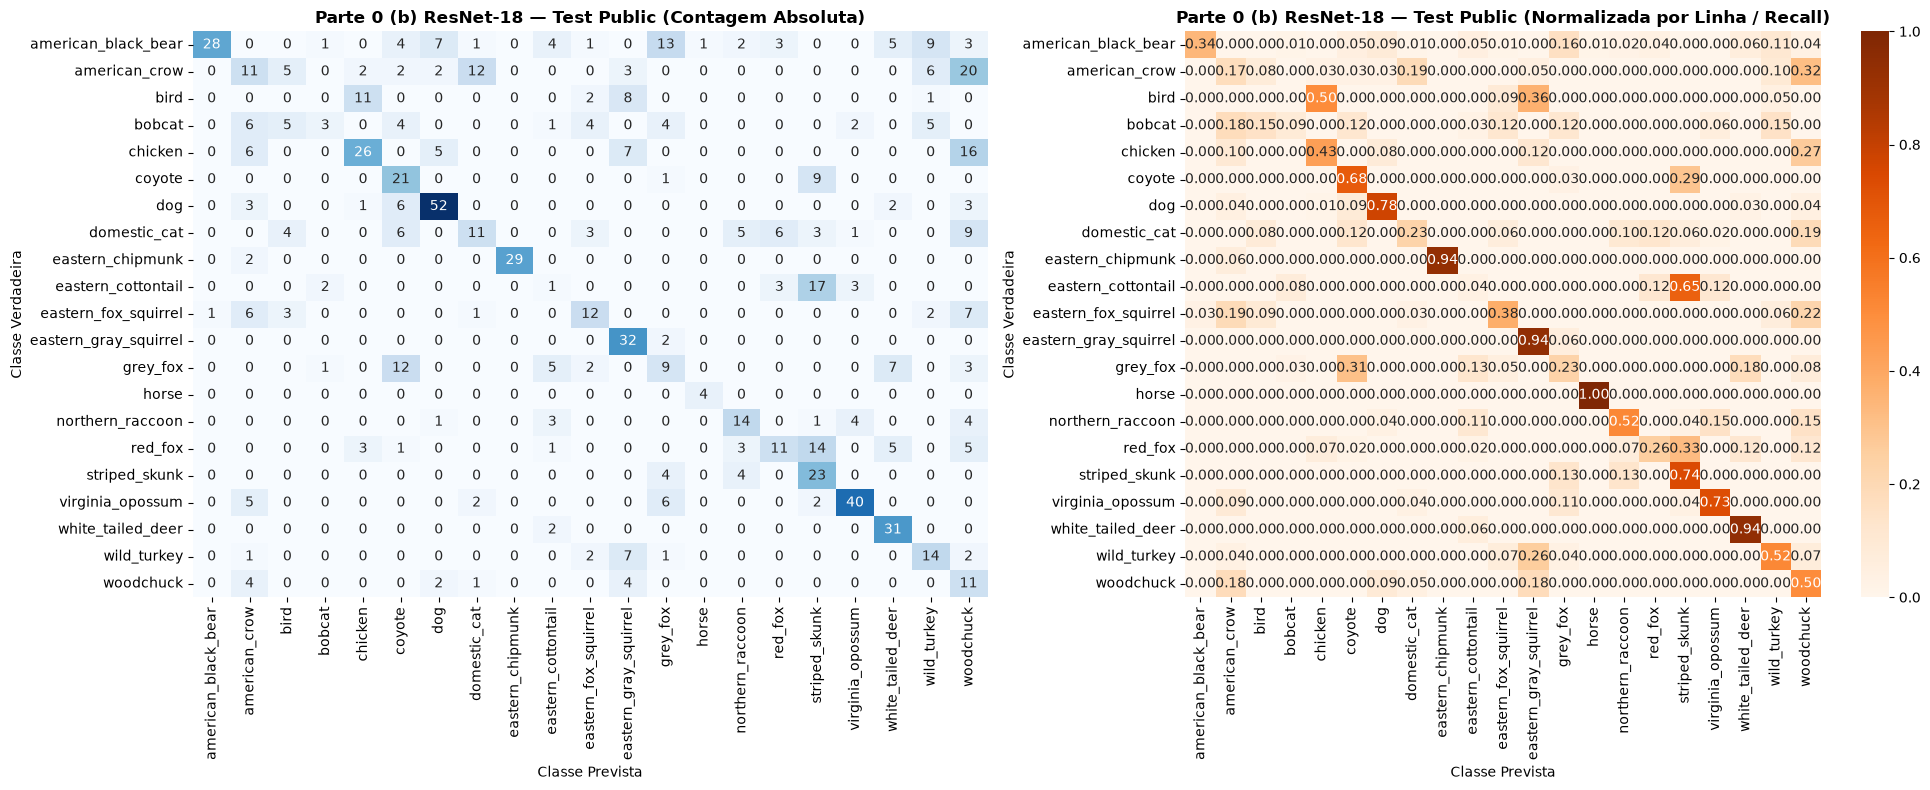

In [9]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints de (a) e (b) no test_public
test_metrics_cnn = evaluate(cnn_zero, test_loader, criterion, device)
test_metrics_res = evaluate(resnet_piso, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "0.1 (a) SmallCNN (do zero)",
        "Parâmetros": count_parameters(cnn_zero),
        "Val F1 Macro (Melhor)": round(hist_cnn["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_cnn["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_cnn["acc"], 4),
    },
    {
        "Modelo": "0.1 (b) ResNet-18 (ImageNet Fine-Tuning)",
        "Parâmetros": count_parameters(resnet_piso),
        "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_res["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_res["acc"], 4),
    }
])
print("Comparativo da Parte 0 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

# Salva o resultado oficial do piso (b) no curva_orcamento.csv
df_orc = log_budget_result(
    csv_path="curva_orcamento.csv",
    metodo="piso",
    orcamento=5,
    seed=42,
    f1_macro=test_metrics_res["f1_macro"],
    acuracia=test_metrics_res["acc"]
)

# Plota a Matriz de Confusão da versão (b) no test_public
plot_confusion_matrix(
    y_true=test_metrics_res["y_true"],
    y_pred=test_metrics_res["y_pred"],
    class_names=class_names,
    title="Parte 0 (b) ResNet-18 — Test Public",
    save_fig="figures/parte0_matriz_confusao_resnet18.png"
)

### 0.3: Curva de treino e validação da versão (b) — Em que época ela começa a decorar?

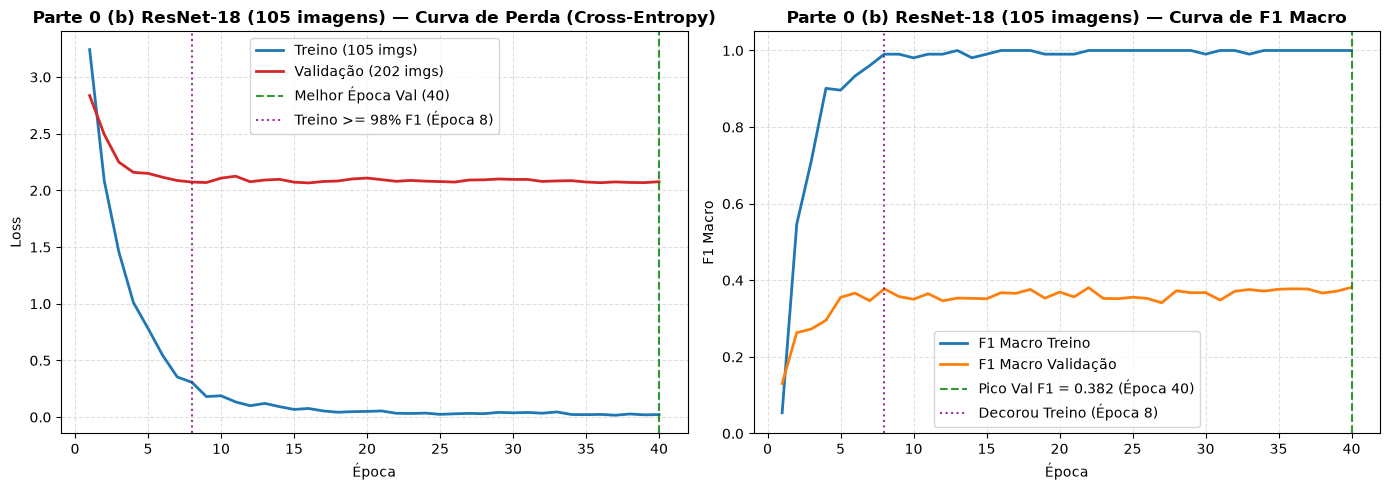

Época em que o treino atingiu >= 98% de F1 Macro: Época 8
Época de pico do F1 Macro na validação:  Época 40


In [10]:
plot_learning_curves(
    hist_resnet,
    title_prefix="Parte 0 (b) ResNet-18 (105 imagens)",
    save_fig="figures/parte0_curvas_resnet18.png"
)

# Diagnóstico numérico automático para responder à pergunta 0.3:
mem_rows = hist_resnet[hist_resnet["train_f1_macro"] >= 0.98]
ep_decorou = int(mem_rows.iloc[0]["epoch"]) if len(mem_rows) > 0 else "N/A"
ep_melhor_val = hist_resnet.attrs["best_epoch"]

print(f"Época em que o treino atingiu >= 98% de F1 Macro: Época {ep_decorou}")
print(f"Época de pico do F1 Macro na validação:  Época {ep_melhor_val}")

# Parte 1 — Usando o que não tem rótulo (Trilha A — Auto-supervisionado):

### 1.0: Carregamento dos dados de treino (Não-Supervisionados)

In [11]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


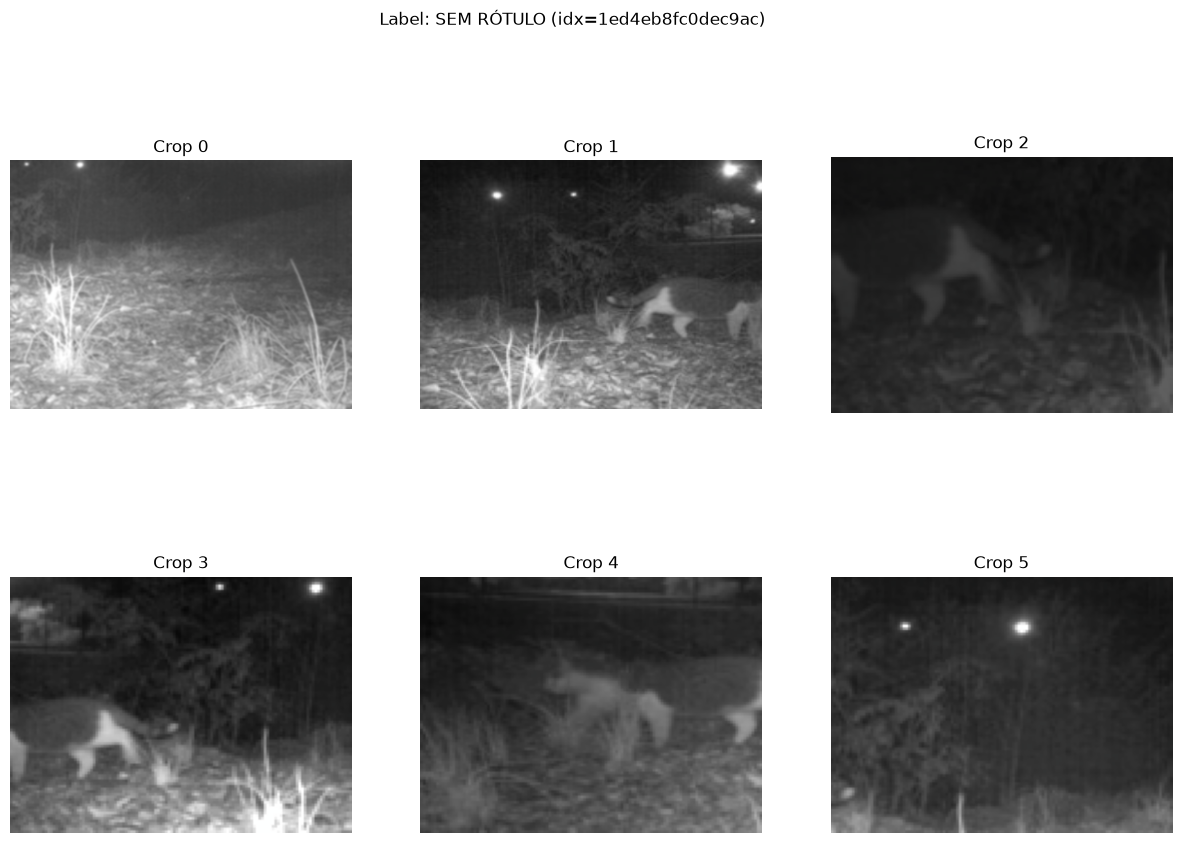

In [12]:
# Baseline: Agressivo e com Multi-Crop (O padrão que deve falhar no ENA24)
swav_transforms_baseline_ena24 = MultiCropDataAugmentation(
    size_crops=[(256, 352), (96, 128)], # Globais e Locais (resolução menor)
    num_crops=[2, 4],                   # 2 visões globais, 4 visões locais
    min_scale=[0.14, 0.05],             # Escalas originais do paper
    max_scale=[1.0, 0.14]
)

# Carrega os dados nao supervisionados
train_loader_unsup_baseline, val_loader_unsup_baseline, test_loader_unsup_baseline = get_unsupervised_dataloaders(
    root_dir=root,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42,
    transform=swav_transforms_baseline_ena24
)

# Visualizando uma amostra do train_loader_unsup_baseline (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_unsup_baseline))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = np.ravel(axes)
for i in range(6):
    img_sample = images[i][0].permute(1, 2, 0).numpy()
    img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    axes[i].imshow(img_sample)
    axes[i].set(title=f"Crop {i}")
    axes[i].axis("off")
    
fig.suptitle(f"Label: {idx_to_label.get(labels[0], "SEM RÓTULO")} (idx={labels[0]})")
plt.show()

In [13]:
# Instancia a baseline pura (para guardar)
imagenet_puro = build_resnet18(pretrained=True)

# Cria um modelo independente na memória para o SwAV modificar
resnet_piso_para_swav = build_resnet18(pretrained=True)

# Instancia aleatoria
imagenet_aleatorio = build_resnet18(pretrained=False)

### 1.1: Continuem o pré-treino do backbone ImageNet com SimCLR ou SwAV sobre as 6.505 imagens do train.  

In [14]:
# Cada época leva alguns minutos; aumente para resultados melhores (ex.: 100+)
EPOCHS = 5

# 1. Instanciar o modelo unificado
swav_model_imagenet_piso = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=resnet_piso_para_swav
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_piso.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_piso.projection_head.parameters()),
    *list(swav_model_imagenet_piso.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        {'params': backbone_params, 'lr': 1e-5},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)

# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_piso = train_swav(
    swav_model_imagenet_piso,
    train_loader_unsup_baseline, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_piso.backbone.state_dict()

Epoch 1/5: 100%|██████████| 407/407 [01:34<00:00,  4.30it/s, loss=4.857]


Epoch: 1 | Loss: 5.141


Epoch 2/5: 100%|██████████| 407/407 [02:05<00:00,  3.25it/s, loss=5.503]


Epoch: 2 | Loss: 4.841


Epoch 3/5: 100%|██████████| 407/407 [02:19<00:00,  2.91it/s, loss=4.834]


Epoch: 3 | Loss: 4.717


Epoch 4/5: 100%|██████████| 407/407 [02:31<00:00,  2.68it/s, loss=4.743]


Epoch: 4 | Loss: 4.648


Epoch 5/5: 100%|██████████| 407/407 [02:42<00:00,  2.50it/s, loss=4.644]

Epoch: 5 | Loss: 4.610


### 1.2: Depois façam avaliação linear e fine-tuning com os 105 rótulos.

##### Obrigatório: avaliação linear com três backbones lado a lado: 
- ImageNet puro;
- ImageNet + auto-supervisionado;
- Aleatório + auto-supervisionado.  

O pré-treino no domínio vale alguma coisa em cima do ImageNet?

In [15]:
# 1. Instanciar o modelo unificado
swav_model_imagenet_aleatorio = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=imagenet_aleatorio
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_aleatorio.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_aleatorio.projection_head.parameters()),
    *list(swav_model_imagenet_aleatorio.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        # MUDEI O LR PARA 1e-3
        {'params': backbone_params, 'lr': 1e-3},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)


# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_aleatorio = train_swav(
    swav_model_imagenet_aleatorio,
    train_loader_unsup_baseline, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_aleatorio.backbone.state_dict()

Epoch 1/5: 100%|██████████| 407/407 [02:45<00:00,  2.46it/s, loss=5.603]


Epoch: 1 | Loss: 5.662


Epoch 2/5: 100%|██████████| 407/407 [01:11<00:00,  5.67it/s, loss=5.589]


Epoch: 2 | Loss: 5.559


Epoch 3/5: 100%|██████████| 407/407 [01:12<00:00,  5.64it/s, loss=5.460]


Epoch: 3 | Loss: 5.498


Epoch 4/5: 100%|██████████| 407/407 [01:10<00:00,  5.79it/s, loss=5.443]


Epoch: 4 | Loss: 5.462


Epoch 5/5: 100%|██████████| 407/407 [01:08<00:00,  5.97it/s, loss=5.602]


Epoch: 5 | Loss: 5.447


In [16]:
# 1. Preparando o backbone da ImageNet pura (removido a 'fc')
backbone_imagenet_puro = nn.Sequential(*list(imagenet_puro.children())[:-1])

# 2. Extraindo os backbones que foram treinados no SwAV
# (Eles já estão no formato certo dentro da classe SwAVModel)
backbone_swav_piso      = trained_swav_model_imagenet_piso.backbone
backbone_swav_aleatorio = trained_swav_model_imagenet_aleatorio.backbone

# 3. Criando os 3 classificadores
probe_baseline       = LinearProbe(backbone=backbone_imagenet_puro, num_classes=21)
probe_swav_imgnet    = LinearProbe(backbone=backbone_swav_piso, num_classes=21)
probe_swav_aleatorio = LinearProbe(backbone=backbone_swav_aleatorio, num_classes=21)

print("Iniciando Avaliação Linear...")

# Rodando para a ImageNet Pura (O Piso)
f1_base, acc_base = train_linear_probe(probe_baseline, train_loader_5, val_loader, device=device)
print(f"[ImageNet Puro] F1-Macro: {f1_base:.4f} | Acurácia: {acc_base:.4f}")

# Rodando para o SwAV a partir da ImageNet
f1_swav, acc_swav = train_linear_probe(probe_swav_imgnet, train_loader_5, val_loader, device=device)
print(f"[SwAV + ImageNet] F1-Macro: {f1_swav:.4f} | Acurácia: {acc_swav:.4f}")

# Rodando para o SwAV a partir do Zero (Aleatório)
f1_rnd, acc_rnd = train_linear_probe(probe_swav_aleatorio, train_loader_5, val_loader, device=device)
print(f"[SwAV + Aleatório] F1-Macro: {f1_rnd:.4f} | Acurácia: {acc_rnd:.4f}")

Iniciando Avaliação Linear...
[ImageNet Puro] F1-Macro: 0.3611 | Acurácia: 0.3663
[SwAV + ImageNet] F1-Macro: 0.3806 | Acurácia: 0.3911
[SwAV + Aleatório] F1-Macro: 0.0749 | Acurácia: 0.1386


In [17]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_baseline       = evaluate(probe_baseline, test_loader, criterion, device)
test_metrics_swav_imgnet    = evaluate(probe_swav_imgnet, test_loader, criterion, device)
test_metrics_swav_aleatorio = evaluate(probe_swav_aleatorio, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet",
        "Parâmetros": count_parameters(probe_baseline),
        # "Val F1 Macro (Melhor)": round(hist_cnn["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_baseline["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_baseline["acc"], 4),
    },
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_imgnet),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet["acc"], 4),
    },
    {
        "Modelo": "ImageNet Aleatório + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_aleatorio),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_aleatorio["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_aleatorio["acc"], 4),
    }
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

# # Salva o resultado oficial do piso (b) no curva_orcamento.csv
# df_orc = log_budget_result(
#     csv_path="curva_orcamento.csv",
#     metodo="piso",
#     orcamento=5,
#     seed=42,
#     f1_macro=test_metrics_res["f1_macro"],
#     acuracia=test_metrics_res["acc"]
# )

# # Plota a Matriz de Confusão da versão (b) no test_public
# plot_confusion_matrix(
#     y_true=test_metrics_res["y_true"],
#     y_pred=test_metrics_res["y_pred"],
#     class_names=class_names,
#     title="Parte 0 (b) ResNet-18 — Test Public",
#     save_fig="figures/parte0_matriz_confusao_resnet18.png"
# )

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet,11187285,0.5138,0.5438
1,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.3963,0.4599
2,ImageNet Aleatório + AutoSupervisionado,11187285,0.0719,0.1196


In [18]:
# 1. Recupera o backbone treinado pelo SwAV (ou ImageNet puro)
# Deepcopy para garantir que o fine-tuning não afete outras avaliações
backbone_swav_para_ft = copy.deepcopy(trained_swav_model_imagenet_piso.backbone)

# 2. Instancia o modelo de fine-tuning
modelo_ft = FineTunedModel(backbone=backbone_swav_para_ft, num_classes=21, dropout_p=0.3)

# 3. Treina usando os dados supervisionados (105 imagens)
modelo_ft_treinado, f1_final, acc_final = train_fine_tuning(
    modelo_ft, 
    train_loader_5,
    val_loader,
    epochs=40,
    device=device
)

Nova melhor F1 Macro: 0.1234 na época 1 | Val Acc: 0.2030
Nova melhor F1 Macro: 0.1826 na época 2 | Val Acc: 0.2723
Nova melhor F1 Macro: 0.2148 na época 3 | Val Acc: 0.2970
Nova melhor F1 Macro: 0.2383 na época 4 | Val Acc: 0.3069
Nova melhor F1 Macro: 0.2942 na época 5 | Val Acc: 0.3465
Nova melhor F1 Macro: 0.3162 na época 8 | Val Acc: 0.3515
Nova melhor F1 Macro: 0.3496 na época 10 | Val Acc: 0.3564
Época 10/40 | Loss Treino: 1.3455 | Val F1: 0.3496 | Val Acc: 0.3564
Nova melhor F1 Macro: 0.3555 na época 16 | Val Acc: 0.3812
Época 20/40 | Loss Treino: 0.7853 | Val F1: 0.3458 | Val Acc: 0.3416
Nova melhor F1 Macro: 0.3756 na época 22 | Val Acc: 0.3861
Época 30/40 | Loss Treino: 0.5044 | Val F1: 0.3686 | Val Acc: 0.3663
Nova melhor F1 Macro: 0.3770 na época 32 | Val Acc: 0.3812
Nova melhor F1 Macro: 0.3781 na época 36 | Val Acc: 0.3812
Época 40/40 | Loss Treino: 0.4726 | Val F1: 0.3729 | Val Acc: 0.3713
--- Fim do Fine-Tuning. Melhor F1 Macro: 0.3781 ---


In [19]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_swav_imgnet_tuned = evaluate(modelo_ft_treinado, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(modelo_ft_treinado),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet_tuned["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet_tuned["acc"], 4),
    },
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.402,0.4488


##### Obrigatório: um experimento sobre aumentação. 
Um random resized crop numa imagem em que o animal ocupa 2% do quadro gera, na maioria das vezes, um par positivo sem animal nenhum. O que a rede aprende a aproximar nesse caso?  
Escolham uma mudança na aumentação, meçam e expliquem.

In [20]:
# Instancia a baseline pura (para guardar)
imagenet_puro_v2 = build_resnet18(pretrained=True)

# Cria uma cópia independente na memória para o SwAV modificar
resnet_piso_para_swav_v2 = build_resnet18(pretrained=True)

# Instancia aleatoria
imagenet_aleatorio_v2 = build_resnet18(pretrained=False)

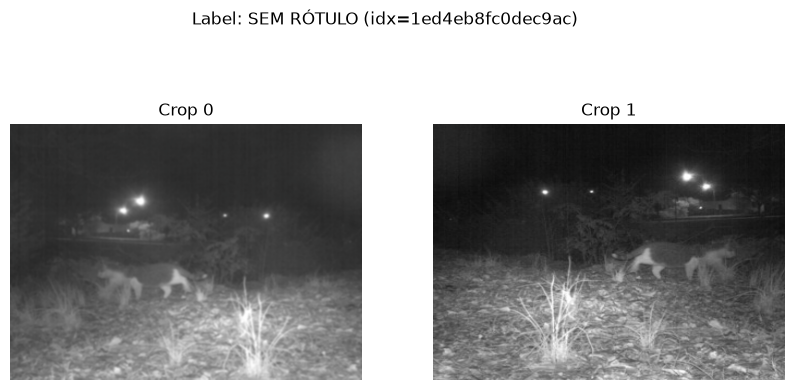

In [21]:
# swav_transforms_ena24 = MultiCropDataAugmentation(
#     size_crops=[(256, 352), (96, 128)], # Globais e Locais (resolução menor)
#     num_crops=[2, 4],                   # 2 visões globais, 4 visões locais
#     min_scale=[0.14, 0.05],             # Escalas originais do paper
#     max_scale=[1.0, 0.14]
# )
swav_transforms_ena24 = MultiCropDataAugmentation(
    size_crops=[(256, 352)],   # Usa a resolução retangular do seu dataset
    num_crops=[2],             # Gera apenas 2 visões globais (sem os crops locais minúsculos)
    min_scale=[0.5],
    max_scale=[1.0]
)

# Carrega os dados nao supervisionados
train_loader_unsup, val_loader_unsup, test_loader_unsup = get_unsupervised_dataloaders(
    root_dir=root,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42,
    transform=swav_transforms_ena24
)

# Visualizando uma amostra do train_loader_unsup (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_unsup))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = np.ravel(axes)
for i in range(2):
    img_sample = images[i][0].permute(1, 2, 0).numpy()
    img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    axes[i].imshow(img_sample)
    axes[i].set(title=f"Crop {i}")
    axes[i].axis("off")
    
fig.suptitle(f"Label: {idx_to_label.get(labels[0], "SEM RÓTULO")} (idx={labels[0]})")
plt.show()

In [22]:
# Cada época leva alguns minutos; aumente para resultados melhores (ex.: 100+)
EPOCHS = 5

# 1. Instanciar o modelo unificado
swav_model_imagenet_piso_v2 = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=resnet_piso_para_swav_v2
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_piso_v2.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_piso_v2.projection_head.parameters()),
    *list(swav_model_imagenet_piso_v2.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        # MUDEI O LR PARA 1e-5
        {'params': backbone_params, 'lr': 1e-5},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)

# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_piso_v2 = train_swav(
    swav_model_imagenet_piso_v2,
    train_loader_unsup, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_piso_v2.backbone.state_dict()

Epoch 1/5: 100%|██████████| 407/407 [00:52<00:00,  7.73it/s, loss=4.140]


Epoch: 1 | Loss: 4.521


Epoch 2/5: 100%|██████████| 407/407 [00:51<00:00,  7.85it/s, loss=4.428]


Epoch: 2 | Loss: 4.210


Epoch 3/5: 100%|██████████| 407/407 [00:49<00:00,  8.19it/s, loss=4.385]


Epoch: 3 | Loss: 4.117


Epoch 4/5: 100%|██████████| 407/407 [00:50<00:00,  8.06it/s, loss=4.502]


Epoch: 4 | Loss: 4.029


Epoch 5/5: 100%|██████████| 407/407 [00:49<00:00,  8.19it/s, loss=4.373]


Epoch: 5 | Loss: 3.999


In [23]:
# 1. Extraindo o backbone que treinado no SwAV
backbone_swav_piso_v2 = trained_swav_model_imagenet_piso_v2.backbone

# 2. Criando o classificador
probe_swav_imgnet_v2 = LinearProbe(backbone=backbone_swav_piso_v2, num_classes=21)

print("Iniciando Avaliação Linear...")

# Rodando para o SwAV a partir da ImageNet
f1_swav, acc_swav = train_linear_probe(probe_swav_imgnet_v2, train_loader_5, val_loader, device=device)
print(f"[SwAV + ImageNet] F1-Macro: {f1_swav:.4f} | Acurácia: {acc_swav:.4f}")

Iniciando Avaliação Linear...
[SwAV + ImageNet] F1-Macro: 0.3792 | Acurácia: 0.3762


In [24]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_swav_imgnet_v2 = evaluate(probe_swav_imgnet_v2, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_imgnet_v2),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet_v2["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet_v2["acc"], 4),
    },
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.4239,0.4649


# Parte 2: A curva de orçamento

### 2.1: 

In [27]:
budgets = [1, 5, 20]
seeds = [42, 123, 999]
methods = ["piso", "trilha_a"]

for metodo in methods:
    for orcamento in budgets:
        for seed in seeds:
            # Pula o experimento (piso, 5, 42) caso já tenha rodado na Parte 0
            if metodo == "piso" and orcamento == 5 and seed == 42:
                print("Pulando (piso, orcamento=5, seed=42) — já executado na Parte 0.")
                continue
                
            print(f"\nRodando | Método: {metodo.upper()} | Orçamento: {orcamento} rótulo(s)/classe | Seed: {seed}")
            
            # 1. Carrega os DataLoaders supervisionados
            train_loader, val_loader, test_loader = get_supervised_dataloaders(
                root_dir=root,
                labels_qtt=orcamento,
                batch_size=16,
                img_size=(256, 352),
                num_workers=2,
                seed=seed
            )
            
            # 2. Constrói o modelo base corretamente
            if metodo == "piso":
                # O piso já carrega a rede inteira com a cabeça de 21 classes
                model = build_model("resnet18", num_classes=21, pretrained=True).to(device)
                
            elif metodo == "trilha_a":
                # Trilha A: precisamos de um backbone "nu" (só as camadas convolucionais, saída 512)
                backbone_nu = models.resnet18(weights=None)
                backbone_nu = nn.Sequential(*list(backbone_nu.children())[:-1])
                
                # Tenta carregar do disco; caso não ache, pega da memória da célula 33 (se existir)
                swav_weights_path = "checkpoints/swav_backbone_v2.pt"
                if os.path.exists(swav_weights_path):
                    backbone_nu.load_state_dict(torch.load(swav_weights_path, weights_only=True))
                else:
                    backbone_nu = copy.deepcopy(trained_swav_model_imagenet_piso_v2.backbone)
                
                # Envolvemos no FineTunedModel que vai adicionar a NOVA cabeça linear
                model = FineTunedModel(backbone=backbone_nu, num_classes=21).to(device)
                
            # 3. Treina o modelo
            model, hist = train_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                device=device,
                model_type="resnet18", # Usa lr_backbone e lr_head separadamente!
                epochs=40,
                lr_backbone=1e-4,
                lr_head=1e-3,
                weight_decay=1e-2,
                save_path=f"checkpoints/{metodo}_b{orcamento}_s{seed}.pt",
                seed=seed,
                verbose=False # Deixa False para não poluir a tela com 18x40 épocas
            )
            
            # 4. Avalia no test_public
            criterion = nn.CrossEntropyLoss()
            metrics = evaluate(model, test_loader, criterion, device)
            
            # 5. Salva no CSV oficial
            df_orc = log_budget_result(
                csv_path="curva_orcamento.csv",
                metodo=metodo,
                orcamento=orcamento,
                seed=seed,
                f1_macro=metrics["f1_macro"],
                acuracia=metrics["acc"]
            )

print("\nCurva de Orçamento concluída! Exibindo tabela consolidada:")
display(pd.read_csv("curva_orcamento.csv"))


Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 42

Treino finalizado. Melhor época no val: 19 (Val F1 Macro = 0.2352)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s42.pt

Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 123

Treino finalizado. Melhor época no val: 33 (Val F1 Macro = 0.2510)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s123.pt

Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 999

Treino finalizado. Melhor época no val: 38 (Val F1 Macro = 0.2221)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s999.pt
Pulando (piso, orcamento=5, seed=42) — já executado na Parte 0.

Rodando | Método: PISO | Orçamento: 5 rótulo(s)/classe | Seed: 123

Treino finalizado. Melhor época no val: 12 (Val F1 Macro = 0.4286)
Pesos do melhor modelo salvos em: checkpoints/piso_b5_s123.pt

Rodando | Método: PISO | Orçamento: 5 rótulo(s)/classe | Seed: 999

Treino finalizado. Melhor época no val: 38 (Val F1 Macro = 0.3765)
Pesos do m

,metodo,orcamento,seed,f1_macro,acuracia
0,piso,1,42,0.2298,0.2503
1,piso,1,123,0.2707,0.2725
2,piso,1,999,0.2264,0.2417
3,piso,5,42,0.4559,0.4723
4,piso,5,123,0.4615,0.4957
5,piso,5,999,0.4253,0.4501
6,piso,20,42,0.6004,0.6375
7,piso,20,123,0.6326,0.6621
8,piso,20,999,0.6595,0.6954
9,trilha_a,1,42,0.2178,0.2491


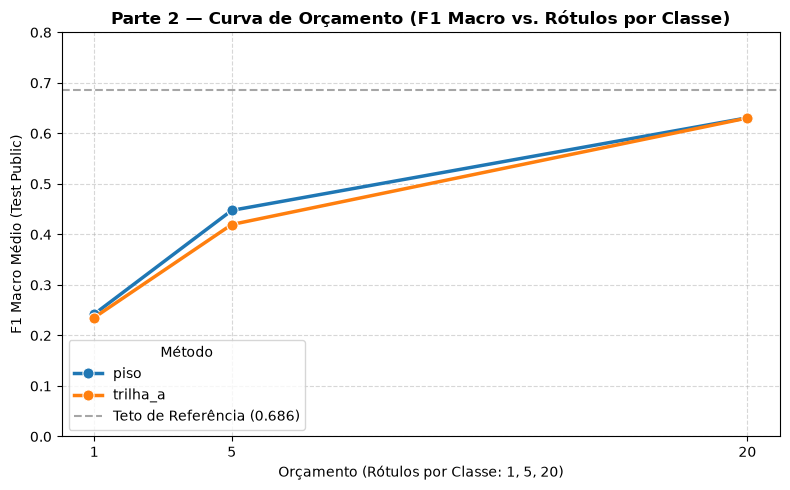

In [28]:
df_budget = pd.read_csv("curva_orcamento.csv")

# Agrupa por método e orçamento calculando média e desvio padrão entre as seeds
df_agg = df_budget.groupby(["metodo", "orcamento"])["f1_macro"].agg(["mean", "std"]).reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df_agg, x="orcamento", y="mean", hue="metodo", 
    marker="o", linewidth=2.5, markersize=8
)

# Adiciona linha horizontal de referência do Teto (0.686)
plt.axhline(0.686, linestyle="--", color="gray", alpha=0.7, label="Teto de Referência (0.686)")

plt.title("Parte 2 — Curva de Orçamento (F1 Macro vs. Rótulos por Classe)", fontsize=12, fontweight="bold")
plt.xlabel("Orçamento (Rótulos por Classe: 1, 5, 20)", fontsize=10)
plt.ylabel("F1 Macro Médio (Test Public)", fontsize=10)
plt.xticks([1, 5, 20])
plt.ylim(0, 0.8)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Método")
plt.tight_layout()
plt.savefig("figures/curva_orcamento_comparativo.png", dpi=150)
plt.show()